# 01 – Keşifsel Veri Analizi (EDA)

**PersonaLens** projesinin ilk adımı: PersonalityCafe MBTI veri setini tanımak.

Bu notebook şu sorulara cevap arar:

1. Veri setinde hangi sütunlar var, kaç kullanıcı var?
2. 16 MBTI tipi ve 4 boyut (E/I, N/S, T/F, J/P) nasıl dağılıyor? Sınıf dengesizliği ne kadar?
3. Train / validation / test ayrımları birbirine benziyor mu?
4. Kullanıcı başına kaç paylaşım ve kaç kelime var?
5. **Veri sızıntısı:** Temizlenmiş metinde hâlâ MBTI kodu kalmış mı?

Veri kaynağı: [Lazanantenaina/personalitycafe-mbti-preprocessed](https://huggingface.co/datasets/Lazanantenaina/personalitycafe-mbti-preprocessed) (CC0).
Ana sürüm olarak `label_clean`, karşılaştırma için `raw` kullanılıyor.

Grafikler `reports/figures/` klasörüne de kaydedilir (dashboard ve sunum için).

In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Proje kökünü import yoluna ekle (notebook notebooks/ klasöründen çalışır)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data_loader import DIMENSIONS, load_mbti

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Veriyi yükleme

İlk çalıştırmada veri Hugging Face'ten indirilir (~80 MB / sürüm) ve `data/raw/` altına kaydedilir. Sonraki çalıştırmalar yerel dosyadan okur.
Her satır **bir kullanıcıyı** temsil eder.

In [2]:
df = load_mbti("label_clean")
raw = load_mbti("raw")

print("label_clean:", df.shape)
print("raw        :", raw.shape)
df.head(3)

label_clean: (8675, 16)
raw        : (8675, 16)


,user_id,type,label,EI,NS,FT,JP,EI_label,NS_label,FT_label,JP_label,posts,text,n_posts,split,variant
0,pc_00000,INFJ,4,I,N,F,J,0,1,0,1,"[' <URL>, <MBTI_TYPE> and <MBTI_TYPE> moments <URL> sportscenter not top ten plays <URL> pranks, What has been the m...",' <URL> <POST_SEP> <MBTI_TYPE> and <MBTI_TYPE> moments <URL> sportscenter not top ten plays <URL> pranks <POST_SEP> ...,38,train,label_clean
1,pc_00003,INTJ,0,I,N,T,J,0,1,1,1,"['Dear <MBTI_TYPE>, I enjoyed our conversation the other day. Esoteric gabbing about the nature of the universe and ...","'Dear <MBTI_TYPE>, I enjoyed our conversation the other day. Esoteric gabbing about the nature of the universe and t...",50,train,label_clean
2,pc_00005,INTJ,0,I,N,T,J,0,1,1,1,"['18/37 @.@, Science is not perfect. No scientist claims that it is, or that scientific information will not be revi...","'18/37 @.@ <POST_SEP> Science is not perfect. No scientist claims that it is, or that scientific information will no...",50,train,label_clean


In [3]:
df.dtypes.to_frame("dtype")

,dtype
user_id,str
type,str
label,int64
EI,str
NS,str
FT,str
JP,str
EI_label,int64
NS_label,int64
FT_label,int64


## 2. Genel bakış ve eksik değer kontrolü

In [4]:
overview = pd.DataFrame({
    "kullanıcı sayısı": [df["user_id"].nunique()],
    "tekrar eden user_id": [df["user_id"].duplicated().sum()],
    "MBTI tipi sayısı": [df["type"].nunique()],
    "toplam paylaşım": [df["n_posts"].sum()],
    "kullanıcı başına ort. paylaşım": [round(df["n_posts"].mean(), 2)],
})
display(overview.T.rename(columns={0: "değer"}))

print("Eksik değerler:")
print(df.drop(columns=["posts"]).isna().sum())

,değer
kullanıcı sayısı,8675.00
tekrar eden user_id,0.00
MBTI tipi sayısı,16.00
toplam paylaşım,408959.00
kullanıcı başına ort. paylaşım,47.14


Eksik değerler:
user_id     0
type        0
label       0
EI          0
NS          0
FT          0
JP          0
EI_label    0
NS_label    0
FT_label    0
JP_label    0
text        0
n_posts     0
split       0
variant     0
dtype: int64


## 3. 16 MBTI tipinin dağılımı

Sınıf dengesizliği modelin en büyük sorunlarından biri olacak.

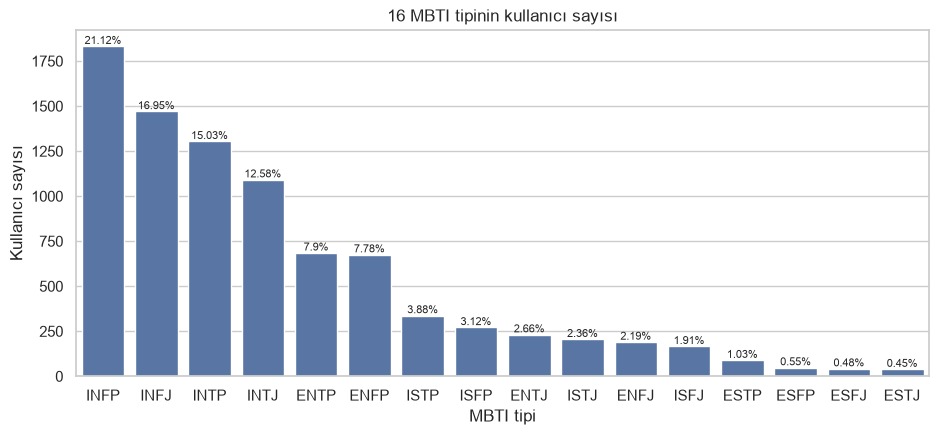

En kalabalık: INFP (1832), en az: ESTJ (39)
Dengesizlik oranı: 46.97 : 1
Sadece en kalabalık tipi tahmin eden 'aptal' modelin doğruluğu: %21.12


In [5]:
type_counts = df["type"].value_counts()
type_share = (type_counts / len(df) * 100).round(2)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(x=type_counts.index, y=type_counts.values, color="#4C72B0", ax=ax)
for i, (n, p) in enumerate(zip(type_counts.values, type_share.values)):
    ax.text(i, n, f"{p}%", ha="center", va="bottom", fontsize=8)
ax.set(title="16 MBTI tipinin kullanıcı sayısı", xlabel="MBTI tipi", ylabel="Kullanıcı sayısı")
save(fig, "01_type_distribution")
plt.show()

ratio = type_counts.max() / type_counts.min()
print(f"En kalabalık: {type_counts.idxmax()} ({type_counts.max()}), "
      f"en az: {type_counts.idxmin()} ({type_counts.min()})")
print(f"Dengesizlik oranı: {ratio:.2f} : 1")
print(f"Sadece en kalabalık tipi tahmin eden 'aptal' modelin doğruluğu: %{type_share.max()}")

## 4. Dört MBTI boyutunun dağılımı

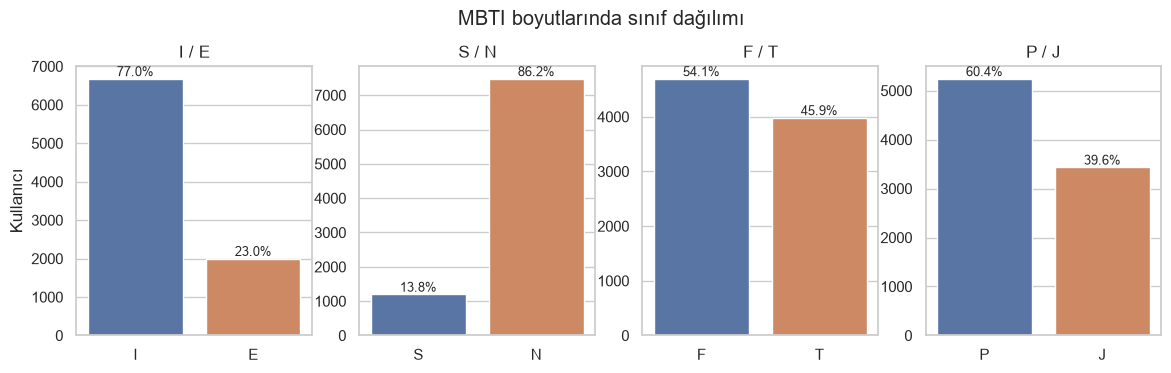

,I,E,çoğunluk oranı,S,N,F,T,P,J
boyut,,,,,,,,,
I/E,6676.0,1999.0,0.770,NaN,NaN,NaN,NaN,NaN,NaN
S/N,NaN,NaN,0.862,1197.0,7478.0,NaN,NaN,NaN,NaN
F/T,NaN,NaN,0.541,NaN,NaN,4694.0,3981.0,NaN,NaN
P/J,NaN,NaN,0.604,NaN,NaN,NaN,NaN,5241.0,3434.0


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
dim_rows = []
for ax, (dim, (neg, pos)) in zip(axes, DIMENSIONS.items()):
    counts = df[dim].value_counts().reindex([neg, pos])
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette=["#4C72B0", "#DD8452"], hue=counts.index, legend=False)
    for i, n in enumerate(counts.values):
        ax.text(i, n, f"{n / len(df):.1%}", ha="center", va="bottom", fontsize=9)
    ax.set(title=f"{neg} / {pos}", xlabel="", ylabel="Kullanıcı" if dim == "EI" else "")
    dim_rows.append({"boyut": f"{neg}/{pos}", neg: counts[neg], pos: counts[pos],
                     "çoğunluk oranı": round(counts.max() / len(df), 3)})
fig.suptitle("MBTI boyutlarında sınıf dağılımı", y=1.04)
save(fig, "02_dimension_distribution")
plt.show()

pd.DataFrame(dim_rows).set_index("boyut")

**Yorum:** Çoğunluk oranı, o boyutta her zaman çoğunluk sınıfını tahmin eden bir modelin doğruluğudur.
Bu yüzden değerlendirmede *accuracy* yerine **Macro-F1** ve **Balanced Accuracy** kullanılmalı.

## 5. Train / validation / test ayrımı

Veri seti kullanıcı bazlı ve tipe göre tabakalı (stratified) bölünmüş. Burada bunu doğruluyoruz.

In [7]:
split_order = ["train", "validation", "test"]
print(df["split"].value_counts().reindex(split_order))

# Aynı kullanıcı birden fazla kümede mi?
users_per_split = {s: set(df.loc[df["split"] == s, "user_id"]) for s in split_order}
overlap = sum(len(users_per_split[a] & users_per_split[b])
              for i, a in enumerate(split_order) for b in split_order[i + 1:])
print("Kümeler arasında ortak kullanıcı sayısı:", overlap)

split_dist = (pd.crosstab(df["type"], df["split"], normalize="columns")[split_order] * 100).round(2)
split_dist.loc[type_counts.index]

split
train         5205
validation    1735
test          1735
Name: count, dtype: int64
Kümeler arasında ortak kullanıcı sayısı: 0


split,train,validation,test
type,,,
INFP,21.11,21.10,21.15
INFJ,16.95,16.95,16.95
INTP,15.02,15.04,15.04
INTJ,12.58,12.56,12.56
ENTP,7.90,7.90,7.90
ENFP,7.78,7.78,7.78
ISTP,3.88,3.92,3.86
ISFP,3.13,3.11,3.11
ENTJ,2.67,2.65,2.65


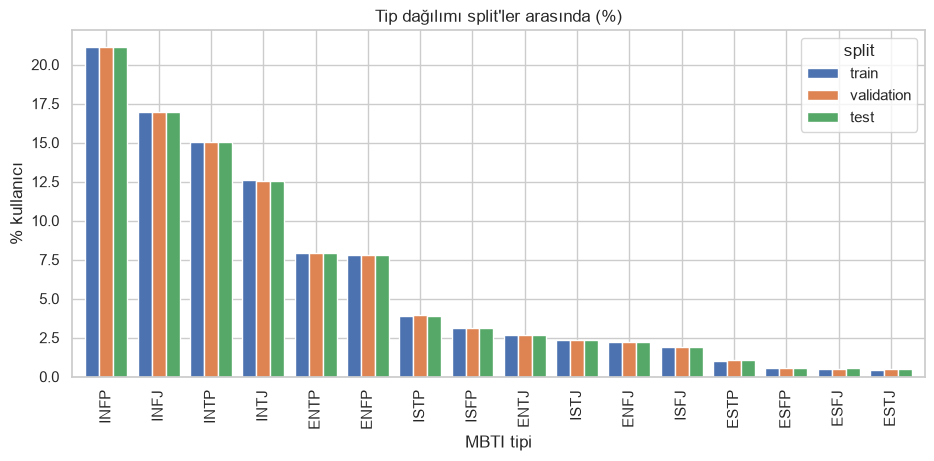

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
split_dist.loc[type_counts.index].plot(kind="bar", ax=ax, width=0.8)
ax.set(title="Tip dağılımı split'ler arasında (%)", xlabel="MBTI tipi", ylabel="% kullanıcı")
ax.legend(title="split")
save(fig, "03_split_distribution")
plt.show()

## 6. Paylaşım ve kelime sayıları

In [9]:
df["n_words"] = df["posts"].apply(lambda ps: sum(len(p.split()) for p in ps))
df["words_per_post"] = df["n_words"] / df["n_posts"]

df[["n_posts", "n_words", "words_per_post"]].describe().round(1)

,n_posts,n_words,words_per_post
count,8675.0,8675.0,8675.0
mean,47.1,1268.9,26.8
std,6.0,315.2,5.3
min,1.0,4.0,2.6
25%,48.0,1090.5,23.6
50%,50.0,1322.0,27.5
75%,50.0,1501.0,30.7
max,51.0,1930.0,38.6


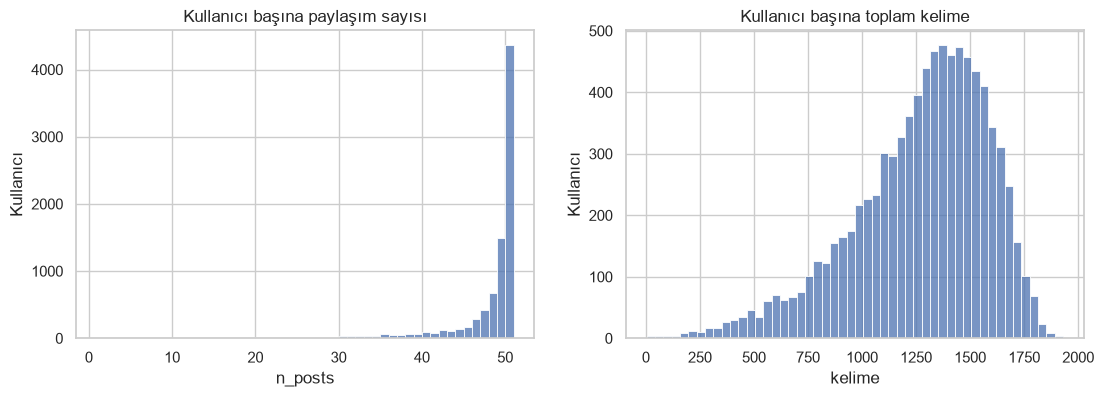

10'dan az paylaşımı olan kullanıcı: 20 (%0.2)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["n_posts"], bins=50, ax=axes[0])
axes[0].set(title="Kullanıcı başına paylaşım sayısı", xlabel="n_posts", ylabel="Kullanıcı")
sns.histplot(df["n_words"], bins=50, ax=axes[1])
axes[1].set(title="Kullanıcı başına toplam kelime", xlabel="kelime", ylabel="Kullanıcı")
save(fig, "04_posts_words_hist")
plt.show()

few = (df["n_posts"] < 10).sum()
print(f"10'dan az paylaşımı olan kullanıcı: {few} (%{few / len(df) * 100:.1f})")

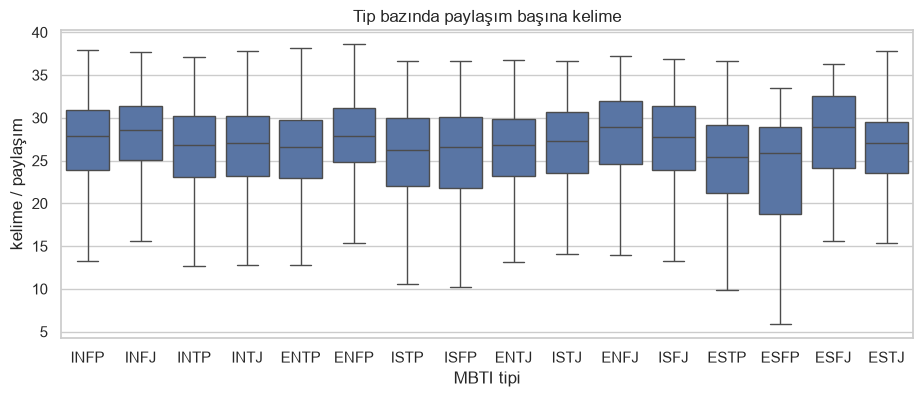

,medyan n_posts,medyan n_words,medyan words_per_post
type,,,
INFP,49.0,1343.0,27.9
INFJ,50.0,1377.0,28.6
INTP,49.0,1290.5,26.8
INTJ,50.0,1290.0,27.0
ENTP,50.0,1286.0,26.6
ENFP,50.0,1345.0,27.8
ISTP,49.0,1267.0,26.2
ISFP,49.0,1236.0,26.6
ENTJ,50.0,1291.0,26.9


In [11]:
per_type = (df.groupby("type")[["n_posts", "n_words", "words_per_post"]]
              .median().round(1).loc[type_counts.index])

fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="type", y="words_per_post", order=type_counts.index, ax=ax, showfliers=False)
ax.set(title="Tip bazında paylaşım başına kelime", xlabel="MBTI tipi", ylabel="kelime / paylaşım")
save(fig, "05_words_per_post_by_type")
plt.show()

per_type.rename(columns=lambda c: f"medyan {c}")

## 7. Veri sızıntısı kontrolü

Dataset card'a göre `label_clean` sürümünde MBTI kodları `<MBTI_TYPE>` ile maskelenmiş.
Ancak maskeleme yalnızca kelimenin **tam halini** yakalıyor olabilir. `INFPs`, `INTJ's`, `INFPness` gibi ekli halleri kontrol ediyoruz.

Eğer kişinin kendi tipi metinde hâlâ yazıyorsa model kişiliği değil, **etiketi okumayı** öğrenir. Bu doğrudan bir sızıntıdır.

In [12]:
TYPE_LIKE = re.compile(r"\b[IE][NS][TF][JP]\w*", re.IGNORECASE)

df["leak_tokens"] = df["text"].str.findall(TYPE_LIKE)
df["n_leak"] = df["leak_tokens"].str.len()
df["own_type_leak"] = [
    sum(tok[:4].upper() == t for tok in toks) for toks, t in zip(df["leak_tokens"], df["type"])
]

leak_summary = pd.Series({
    "metninde tip benzeri kod kalan kullanıcı": (df["n_leak"] > 0).sum(),
    "  kod kalan oran (%)": round((df["n_leak"] > 0).mean() * 100, 1),
    "KENDİ tipi metninde geçen kullanıcı": (df["own_type_leak"] > 0).sum(),
    "  kendi tipi oran (%)": round((df["own_type_leak"] > 0).mean() * 100, 1),
    "toplam kalan kod sayısı": df["n_leak"].sum(),
})
leak_summary.to_frame("label_clean")

,label_clean
metninde tip benzeri kod kalan kullanıcı,5528.0
kod kalan oran (%),63.7
KENDİ tipi metninde geçen kullanıcı,4215.0
kendi tipi oran (%),48.6
toplam kalan kod sayısı,22731.0


In [13]:
leak_counter = Counter(tok.lower() for toks in df["leak_tokens"] for tok in toks)
pd.DataFrame(leak_counter.most_common(25), columns=["kalan ifade", "adet"])

,kalan ifade,adet
0,infps,3435
1,intjs,3048
2,infjs,2861
3,intps,2620
4,enfps,1990
5,entps,1902
6,entjs,914
7,enfjs,863
8,istps,817
9,istjs,695


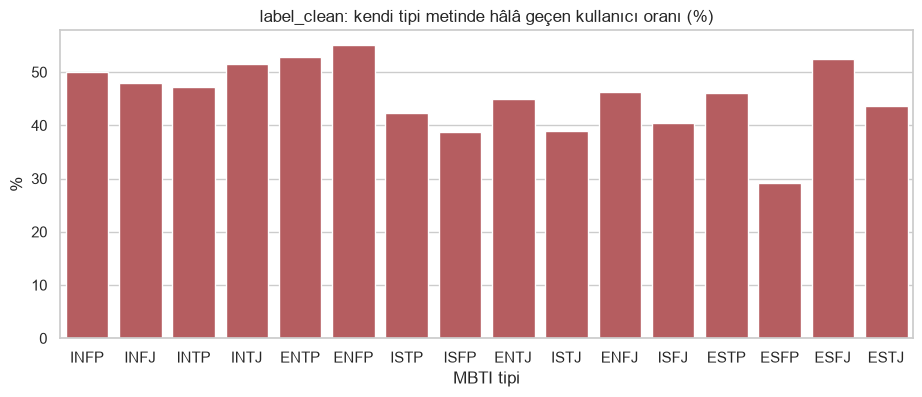

In [14]:
# Tip başına sızıntı oranı: hangi tiplerde kişi kendi tipini daha çok yazıyor?
own_leak_by_type = (df.groupby("type")["own_type_leak"].apply(lambda s: (s > 0).mean() * 100)
                      .round(1).loc[type_counts.index])

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(x=own_leak_by_type.index, y=own_leak_by_type.values, color="#C44E52", ax=ax)
ax.set(title="label_clean: kendi tipi metinde hâlâ geçen kullanıcı oranı (%)",
       xlabel="MBTI tipi", ylabel="%")
save(fig, "06_own_type_leak_by_type")
plt.show()

### `raw` ile karşılaştırma

`raw` sürümünde hiç maskeleme yok. `label_clean`'de `<MBTI_TYPE>` kaç kez kullanılmış ve ham veride kaç kod vardı?

In [15]:
raw_leak = raw["text"].str.count(TYPE_LIKE)
comparison = pd.DataFrame({
    "raw": {
        "tip benzeri kod (toplam)": raw_leak.sum(),
        "kodu olan kullanıcı (%)": round((raw_leak > 0).mean() * 100, 1),
        "<MBTI_TYPE> maskesi": 0,
    },
    "label_clean": {
        "tip benzeri kod (toplam)": df["n_leak"].sum(),
        "kodu olan kullanıcı (%)": round((df["n_leak"] > 0).mean() * 100, 1),
        "<MBTI_TYPE> maskesi": df["text"].str.count("<MBTI_TYPE>").sum(),
    },
})
comparison

,raw,label_clean
tip benzeri kod (toplam),124656.0,22731.0
kodu olan kullanıcı (%),95.9,63.7
<MBTI_TYPE> maskesi,0.0,105736.0


## 8. Bulgular ve sonraki adımlar

Aşağıdaki hücre bulguları sayılarla özetler. Bu notlar ekip toplantısı, rapor ve sunum için kullanılabilir.

In [16]:
majority = {f"{n}/{p}": df[d].value_counts(normalize=True).max() for d, (n, p) in DIMENSIONS.items()}

print("BULGULAR")
print(f"- {len(df)} kullanıcı, {df['n_posts'].sum():,} paylaşım; kullanıcı başına ort. {df['n_posts'].mean():.1f} paylaşım.")
print(f"- 16 tip arasında dengesizlik {ratio:.1f}:1 (en çok {type_counts.idxmax()}, en az {type_counts.idxmin()}).")
print("- Boyutlarda çoğunluk oranları: " + ", ".join(f"{k} %{v * 100:.1f}" for k, v in majority.items()))
print(f"- Split'ler arasında ortak kullanıcı: {overlap}.")
print(f"- label_clean'de kullanıcıların %{(df['own_type_leak'] > 0).mean() * 100:.1f}'inin metninde KENDİ tipi hâlâ geçiyor "
      f"(çoğunlukla 'INFPs' gibi ekli haller).")
print()
print("SONRAKİ ADIMLAR")
print("1. ETL'de ekli MBTI kodlarını da maskele (ör. regex: \\b[IE][NS][TF][JP]\\w*) ve yeniden ölç.")
print("2. Modellerde class_weight='balanced' kullan; Macro-F1 ve Balanced Accuracy raporla.")
print("3. Hazır user-level split'i kullan; test setini yalnızca final değerlendirmede aç.")
print("4. Bu grafikleri (reports/figures) dashboard'un veri profili sayfasına taşı.")

BULGULAR
- 8675 kullanıcı, 408,959 paylaşım; kullanıcı başına ort. 47.1 paylaşım.
- 16 tip arasında dengesizlik 47.0:1 (en çok INFP, en az ESTJ).
- Boyutlarda çoğunluk oranları: I/E %77.0, S/N %86.2, F/T %54.1, P/J %60.4
- Split'ler arasında ortak kullanıcı: 0.
- label_clean'de kullanıcıların %48.6'inin metninde KENDİ tipi hâlâ geçiyor (çoğunlukla 'INFPs' gibi ekli haller).

SONRAKİ ADIMLAR
1. ETL'de ekli MBTI kodlarını da maskele (ör. regex: \b[IE][NS][TF][JP]\w*) ve yeniden ölç.
2. Modellerde class_weight='balanced' kullan; Macro-F1 ve Balanced Accuracy raporla.
3. Hazır user-level split'i kullan; test setini yalnızca final değerlendirmede aç.
4. Bu grafikleri (reports/figures) dashboard'un veri profili sayfasına taşı.
